# Shadow-ArUco dictionary diagnosis

Goal: determine which OpenCV ArUco dictionary Shadow-ArUco uses, **without relying on the detector**.

The previous sweep returned 0/2400 for all dictionaries. That is a *detection* result, not a
*dictionary* result. This notebook separates the two by warping ground-truth corners to a
canonical square and reading the bit grid directly.

Prior evidence that the dictionary is a standard OpenCV one: the DeepArUco++ paper states the
Shadow-ArUco ground truth was generated by running classical ArUco with ECB=0 and manually adding
the markers it missed. Those IDs came from OpenCV.

**Run order:** Cell 1, restart the runtime when prompted, then Cell 2 onward.

## 1. Clean OpenCV environment

The previous notebook layered `opencv-contrib-python 4.7` under `opencv-python-headless 5.0`
and never restarted. Install exactly ONE opencv package. `opencv-contrib-python` already
contains everything in `opencv-python` plus contrib, so never install both.

**After this cell finishes, restart the runtime before running anything else.**

In [1]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless -q
!pip install -q opencv-contrib-python==4.10.0.84
print("\n>>> RESTART THE RUNTIME NOW (Runtime > Restart session), then continue from Cell 2.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 11.5 MB/s eta 0:00:00

>>> RESTART THE RUNTIME NOW (Runtime > Restart session), then continue from Cell 2.


## 2. Verify the environment

If this cell does not print 4.10.0 with all three checks True, stop and fix it before continuing.

In [3]:
import cv2, numpy as np, json, glob, os, itertools

print("cv2 version      :", cv2.__version__)
print("has aruco        :", hasattr(cv2, "aruco"))
print("has ArucoDetector:", hasattr(cv2.aruco, "ArucoDetector"))
print("has generateImage:", hasattr(cv2.aruco, "generateImageMarker"))
assert cv2.__version__.startswith("4.10"), "Wrong OpenCV. Re-run cell 1 and restart the runtime."

ROOT = "/content/video_1"   # adjust if you extracted elsewhere
assert os.path.isdir(ROOT), f"{ROOT} not found"
print("\nroot ok:", ROOT)

cv2 version      : 4.10.0
has aruco        : True
has ArucoDetector: True
has generateImage: True

root ok: /content/video_1


In [2]:
import os, hashlib, subprocess
from google.colab import drive
drive.mount('/content/drive')

CACHE = '/content/drive/MyDrive/shadow_aruco'
TAR   = f'{CACHE}/video_1.tar.gz'
MD5   = '1c8bd58fb067a453487dfff783416674'   # from the Zenodo record
os.makedirs(CACHE, exist_ok=True)

def md5sum(p, chunk=1 << 20):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

if not os.path.exists(TAR) or md5sum(TAR) != MD5:
    print('downloading (~7 min, once only)...')
    subprocess.run(['curl', '-L', '-o', TAR,
                    'https://zenodo.org/records/10791293/files/video_1.tar.gz'], check=True)
    got = md5sum(TAR)
    assert got == MD5, f'checksum mismatch: {got} != {MD5} — truncated download'
    print('verified')
else:
    print('cached copy verified')

os.chdir('/content')
subprocess.run(['tar', '-xzf', TAR], check=True)
ROOT = '/content/video_1'
assert os.path.isdir(ROOT)
print('frames:', len(os.listdir(ROOT)) - 1)

Mounted at /content/drive
downloading (~7 min, once only)...
verified
frames: 1433


## 3. Inspect the annotation schema

Do not assume the field names. Print one JSON in full, then summarise the ID range across the
whole sequence. The ID range alone constrains the dictionary size (e.g. max ID 49 rules out
nothing, but max ID 700 rules out every `_50`, `_100` and `_250` dictionary).

In [4]:
frames = sorted(glob.glob(os.path.join(ROOT, "*.png")))
pairs = []
for f in frames:
    idx = os.path.splitext(os.path.basename(f))[0]
    j = os.path.join(ROOT, "corrected_annotations", f"{idx}.json")
    if os.path.exists(j):
        pairs.append((f, j))
print("pairs:", len(pairs))

print("\n--- full first annotation ---")
with open(pairs[0][1]) as fp:
    sample = json.load(fp)
print(json.dumps(sample, indent=2)[:2500])

all_ids, per_frame = set(), []
for _, j in pairs:
    with open(j) as fp:
        g = json.load(fp)
    ms = g["markers"]
    per_frame.append(len(ms))
    all_ids.update(int(m["id"]) for m in ms)

print("\nunique IDs :", sorted(all_ids))
print("n unique   :", len(all_ids))
print("ID range   :", min(all_ids), "-", max(all_ids))
print("markers/frame: mean %.2f  min %d  max %d" % (np.mean(per_frame), min(per_frame), max(per_frame)))

pairs: 1433

--- full first annotation ---
{
  "markers": [
    {
      "id": 238,
      "corners": [
        {
          "x": 537.8920288085938,
          "y": 203.9147186279297
        },
        {
          "x": 580.7891845703125,
          "y": 256.67852783203125
        },
        {
          "x": 525.3497924804688,
          "y": 289.23260498046875
        },
        {
          "x": 481.758056640625,
          "y": 233.31109619140625
        }
      ]
    },
    {
      "id": 239,
      "corners": [
        {
          "x": 233.5710906982422,
          "y": 297.7716979980469
        },
        {
          "x": 140.66725158691406,
          "y": 279.6771240234375
        },
        {
          "x": 173.2148895263672,
          "y": 209.23098754882812
        },
        {
          "x": 259.9620056152344,
          "y": 228.16184997558594
        }
      ]
    },
    {
      "id": 240,
      "corners": [
        {
          "x": 626.087158203125,
          "y": 129.808349609375
  

## 4. Locate the corner field and normalise it

Corners may be stored flat (`[x1,y1,x2,y2,...]`) or nested (`[[x,y],...]`), under any of several
key names. This finds the right one and returns a (4,2) float array in the order stored.

If it raises, read the schema dump above and add the key name to `CORNER_KEYS`.

In [6]:
CORNER_KEYS = ["corners", "points", "coords", "coordinates", "pts", "corner", "quad"]

def get_corners(marker):
    for k in CORNER_KEYS:
        if k in marker:
            corners_data = marker[k]
            # Check if the corners are given as a list of dictionaries with 'x' and 'y' keys
            if isinstance(corners_data, list) and corners_data and isinstance(corners_data[0], dict):
                extracted_coords = []
                for pt in corners_data:
                    extracted_coords.append(pt['x'])
                    extracted_coords.append(pt['y'])
                v = np.asarray(extracted_coords, dtype=np.float32)
            else:
                # Assume it's already a flat list or nested list of numerical coordinates
                v = np.asarray(corners_data, dtype=np.float32)

            if v.size != 8:
                raise ValueError(f"key '{k}' has {v.size} values, expected 8")
            return v.reshape(4, 2)
    raise KeyError(f"No corner key found. Marker keys: {list(marker.keys())}")

m0 = sample["markers"][0]
print("marker keys:", list(m0.keys()))
print("corners:\n", get_corners(m0))

marker keys: ['id', 'corners']
corners:
 [[537.892   203.91472]
 [580.7892  256.67853]
 [525.3498  289.2326 ]
 [481.75806 233.3111 ]]


## 5. Brightness ranking

The previous run used `pairs[:200]` — the first 200 frames of a sequence shot in a darkened room.
Rank by median luma and keep the brightest, which is where classical ArUco has any chance.

In [7]:
lumas = []
for f, j in pairs:
    g = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    lumas.append((float(np.median(g)), f, j))
lumas.sort(reverse=True)

vals = np.array([l[0] for l in lumas])
print("median luma across sequence:")
for p in [0, 10, 25, 50, 75, 90, 100]:
    print(f"  p{p:<3d} {np.percentile(vals, p):6.1f}")

BRIGHT = lumas[:200]
print(f"\nbrightest 200: luma {BRIGHT[-1][0]:.1f} - {BRIGHT[0][0]:.1f}")
print(f"first 200 (what was used before): luma median {np.median([np.median(cv2.imread(f, 0)) for f, _ in pairs[:200]]):.1f}")

median luma across sequence:
  p0      8.0
  p10    10.0
  p25    13.0
  p50    31.0
  p75    41.0
  p90    66.0
  p100  102.0

brightest 200: luma 65.0 - 102.0
first 200 (what was used before): luma median 13.0


## 6. Look at the markers

The single most informative step, and it takes ten seconds. Rectify markers from ground-truth
corners and display them.

A standard ArUco marker has a solid black border one cell thick on all four sides, with the
data grid inside. If you can see that structure, the markers are standard and the dictionary
question is answerable. Count the data cells across one edge — that is `n` in DICT_nXn_*.

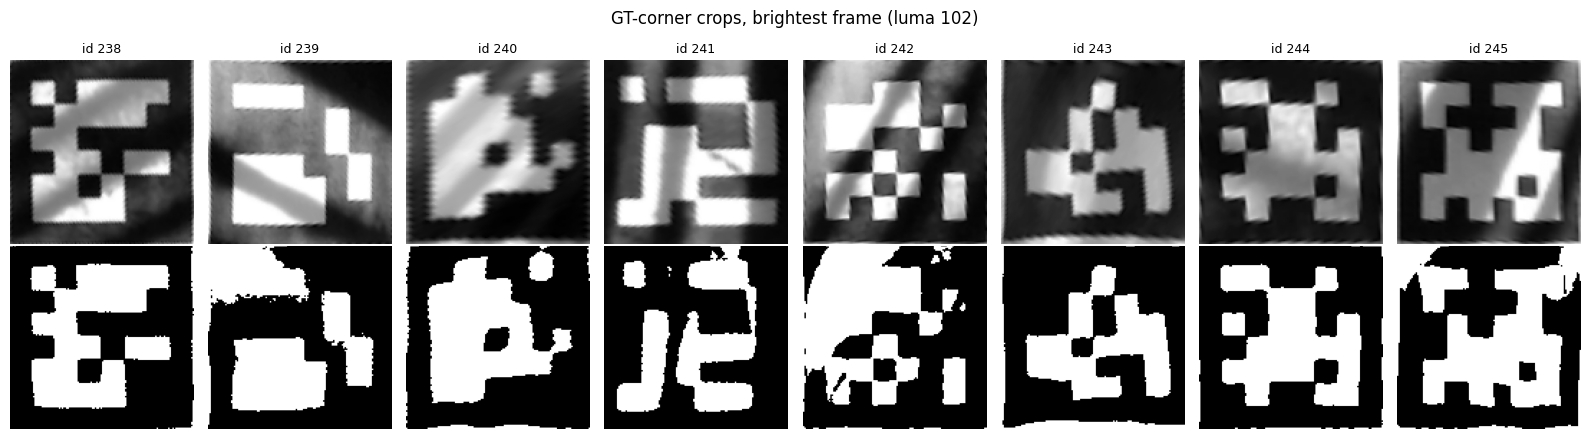

In [8]:
import matplotlib.pyplot as plt

def rectify(gray, corners, out_px=128):
    dst = np.array([[0, 0], [out_px-1, 0], [out_px-1, out_px-1], [0, out_px-1]], dtype=np.float32)
    H = cv2.getPerspectiveTransform(corners.astype(np.float32), dst)
    return cv2.warpPerspective(gray, H, (out_px, out_px), flags=cv2.INTER_LINEAR)

f, j = BRIGHT[0][1], BRIGHT[0][2]
gray = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
with open(j) as fp:
    g = json.load(fp)

n_show = min(8, len(g["markers"]))
fig, axes = plt.subplots(2, n_show, figsize=(2*n_show, 4.5))
for k in range(n_show):
    m = g["markers"][k]
    crop = rectify(gray, get_corners(m))
    axes[0, k].imshow(crop, cmap="gray"); axes[0, k].set_title(f"id {m['id']}", fontsize=9)
    _, bw = cv2.threshold(crop, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    axes[1, k].imshow(bw, cmap="gray")
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[0, 0].set_ylabel("raw"); axes[1, 0].set_ylabel("otsu")
plt.suptitle(f"GT-corner crops, brightest frame (luma {BRIGHT[0][0]:.0f})")
plt.tight_layout(); plt.show()

## 7. Read bits from GT corners and match against every dictionary

This is the decisive test. The detector plays no part.

For a DICT_nXn dictionary the marker is `(n+2) x (n+2)` cells including the black border, so we
warp to that grid, sample each cell centre, Otsu-threshold, and take the inner `n x n` as data
bits. We then compare against the canonical bits of the ground-truth ID under all four rotations
and record the minimum Hamming distance.

**Reading the output:** the correct dictionary shows a large fraction at Hamming 0. Wrong
dictionaries scatter around `n*n/2`. If *every* dictionary scatters, the markers are non-standard
— but check the images in Cell 6 first, because a corner-ordering or border-convention mismatch
looks identical to a dictionary mismatch in this metric.

In [9]:
CELL_PX = 12

def read_bits(gray, corners, n):
    """Warp to an (n+2)x(n+2) cell grid and return the inner n x n data bits."""
    total = (n + 2) * CELL_PX
    sq = rectify(gray, corners, total)
    _, bw = cv2.threshold(sq, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    bits = np.zeros((n, n), dtype=np.uint8)
    pad = CELL_PX // 4
    for r in range(n):
        for c in range(n):
            y0, x0 = (r + 1) * CELL_PX, (c + 1) * CELL_PX
            cellpx = bw[y0+pad:y0+CELL_PX-pad, x0+pad:x0+CELL_PX-pad]
            bits[r, c] = 1 if cellpx.mean() > 127 else 0
    return bits

def canonical_bits(dict_id, marker_id, n):
    d = cv2.aruco.getPredefinedDictionary(dict_id)
    if marker_id >= d.bytesList.shape[0]:
        return None
    total = (n + 2) * CELL_PX
    img = cv2.aruco.generateImageMarker(d, int(marker_id), total)
    bits = np.zeros((n, n), dtype=np.uint8)
    pad = CELL_PX // 4
    for r in range(n):
        for c in range(n):
            y0, x0 = (r + 1) * CELL_PX, (c + 1) * CELL_PX
            bits[r, c] = 1 if img[y0+pad:y0+CELL_PX-pad, x0+pad:x0+CELL_PX-pad].mean() > 127 else 0
    return bits

DICTS = {
    "DICT_4X4_50": (cv2.aruco.DICT_4X4_50, 4), "DICT_4X4_100": (cv2.aruco.DICT_4X4_100, 4),
    "DICT_4X4_250": (cv2.aruco.DICT_4X4_250, 4), "DICT_4X4_1000": (cv2.aruco.DICT_4X4_1000, 4),
    "DICT_5X5_50": (cv2.aruco.DICT_5X5_50, 5), "DICT_5X5_100": (cv2.aruco.DICT_5X5_100, 5),
    "DICT_5X5_250": (cv2.aruco.DICT_5X5_250, 5), "DICT_5X5_1000": (cv2.aruco.DICT_5X5_1000, 5),
    "DICT_6X6_50": (cv2.aruco.DICT_6X6_50, 6), "DICT_6X6_100": (cv2.aruco.DICT_6X6_100, 6),
    "DICT_6X6_250": (cv2.aruco.DICT_6X6_250, 6), "DICT_6X6_1000": (cv2.aruco.DICT_6X6_1000, 6),
    "DICT_7X7_50": (cv2.aruco.DICT_7X7_50, 7), "DICT_7X7_100": (cv2.aruco.DICT_7X7_100, 7),
    "DICT_7X7_250": (cv2.aruco.DICT_7X7_250, 7), "DICT_7X7_1000": (cv2.aruco.DICT_7X7_1000, 7),
    "DICT_ARUCO_ORIGINAL": (cv2.aruco.DICT_ARUCO_ORIGINAL, 5),
}

SAMPLE = BRIGHT[:60]
print(f"Matching bits from GT corners over {len(SAMPLE)} brightest frames\n")
print(f"{'dictionary':<22}{'markers':>9}{'H=0':>8}{'H<=1':>8}{'H<=3':>8}{'meanH':>9}")
print("-" * 64)

summary = []
for name, (did, n) in DICTS.items():
    canon_cache, dists = {}, []
    for _, f, j in SAMPLE:
        gy = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        with open(j) as fp:
            gg = json.load(fp)
        for m in gg["markers"]:
            mid = int(m["id"])
            if mid not in canon_cache:
                canon_cache[mid] = canonical_bits(did, mid, n)
            ref = canon_cache[mid]
            if ref is None:
                continue
            obs = read_bits(gy, get_corners(m), n)
            best = min(int(np.sum(np.rot90(obs, k) != ref)) for k in range(4))
            dists.append(best)
    if not dists:
        print(f"{name:<22}{'--- all IDs out of range ---':>41}")
        continue
    d = np.array(dists)
    row = (name, len(d), (d == 0).mean(), (d <= 1).mean(), (d <= 3).mean(), d.mean())
    summary.append(row)
    print(f"{name:<22}{len(d):>9}{(d==0).mean():>8.1%}{(d<=1).mean():>8.1%}{(d<=3).mean():>8.1%}{d.mean():>9.2f}")

if summary:
    best = max(summary, key=lambda r: r[2])
    print(f"\nBest exact-match dictionary: {best[0]}  ({best[2]:.1%} at Hamming 0)")

Matching bits from GT corners over 60 brightest frames

dictionary              markers     H=0    H<=1    H<=3    meanH
----------------------------------------------------------------
DICT_4X4_50                        --- all IDs out of range ---
DICT_4X4_100                       --- all IDs out of range ---
DICT_4X4_250                720    0.0%    0.0%    1.1%     6.16
DICT_4X4_1000               720    0.0%    0.0%    1.1%     6.16
DICT_5X5_50                        --- all IDs out of range ---
DICT_5X5_100                       --- all IDs out of range ---
DICT_5X5_250                720    0.0%    0.0%    0.0%     9.48
DICT_5X5_1000               720    0.0%    0.0%    0.0%     9.48
DICT_6X6_50                        --- all IDs out of range ---
DICT_6X6_100                       --- all IDs out of range ---
DICT_6X6_250                720    0.0%    0.0%    0.0%    15.17
DICT_6X6_1000               720    0.0%    0.0%    0.0%    15.17
DICT_7X7_50                        --- a

## 8. Detector sweep on bright frames, for the record

Now run the actual detector on the brightest frames. The expected outcome, given the dataset was
built specifically to defeat classical methods, is a low but **non-zero** rate. That number is a
legitimate result for the paper: it is the classical baseline on Shadow-ArUco.

Run this only after Cell 7 has told you which dictionary to use.

In [10]:
DICT_NAME = "DICT_6X6_250"   # <-- set from Cell 7 result
did, n = DICTS[DICT_NAME]

d = cv2.aruco.getPredefinedDictionary(did)
det = cv2.aruco.ArucoDetector(d, cv2.aruco.DetectorParameters())

tp = fp_ = gt_total = frames_with = 0
for _, f, j in BRIGHT:
    gy = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    corners, ids, _ = det.detectMarkers(gy)
    with open(j) as fpp:
        gg = json.load(fpp)
    gt_ids = [int(m["id"]) for m in gg["markers"]]
    gt_total += len(gt_ids)
    if ids is not None and len(ids):
        frames_with += 1
        for i in ids.flatten().tolist():
            if int(i) in gt_ids:
                tp += 1
            else:
                fp_ += 1

print(f"dictionary        : {DICT_NAME}")
print(f"frames            : {len(BRIGHT)}  (with >=1 detection: {frames_with})")
print(f"GT markers        : {gt_total}")
print(f"correct ID hits   : {tp}   recall {tp/max(gt_total,1):.3f}")
print(f"false IDs         : {fp_}")
print("\nA low non-zero recall here is the expected, reportable classical baseline.")
print("Exactly zero across bright frames means something is still misconfigured.")

dictionary        : DICT_6X6_250
frames            : 200  (with >=1 detection: 0)
GT markers        : 2400
correct ID hits   : 0   recall 0.000
false IDs         : 0

A low non-zero recall here is the expected, reportable classical baseline.
Exactly zero across bright frames means something is still misconfigured.
